# ДЗ 4.2. Нить между опорами — зелёный уровень

## Постановка задачи

Рассматривается однородная тяжёлая гибкая нерастяжимая нить, закреплённая между двумя опорами.
Форма равновесия удовлетворяет уравнению

$$
y'' = \frac{1}{a}\sqrt{1 + (y')^2}, \qquad a = \frac{H}{q} > 0,
$$

где:

- $H$ — горизонтальная составляющая натяжения,
- $q$ — вес единицы длины нити,
- $a$ — характерный масштаб, выраженный в единицах расстояния между опорами.

## Краевая задача

При $a = 1$ решаем задачу

$$
y(0) = 0, \qquad y(1) = 0,
$$

подбирая **начальный наклон** $s = y'(0)$.

## Точное решение

$$
y(x) = \cosh\!\left(x - \tfrac{1}{2}\right) - \cosh\!\left(\tfrac{1}{2}\right).
$$

Тогда

$$
y'(0) = \sinh\!\left(-\tfrac{1}{2}\right) = -\sinh\!\left(\tfrac{1}{2}\right) \approx -0.5211.
$$

## Метод стрельбы

Сводим краевую задачу к поиску корня невязки

$$
R(s) = y(1; s) - 0 = 0.
$$

Для каждого пробного $s$ интегрируем задачу Коши и вычисляем $R(s)$.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ---------- Задача Коши для нити ----------
def integrate_chain(s, a=1.0, T=1.0, rtol=1e-10, atol=1e-12):
    """y'' = (1/a)·sqrt(1 + (y')^2), y(0)=0, y'(0)=s.
    Возвращает y(T)."""
    def rhs(t, y):
        return [y[1], (1.0 / a) * np.sqrt(1.0 + y[1]**2)]
    sol = solve_ivp(rhs, [0, T], [0.0, s], method='RK45',
                    rtol=rtol, atol=atol)
    return sol.y[0, -1]

def residual(s, a=1.0, T=1.0, **kw):
    """Невязка на правой опоре: R(s) = y(T; s)."""
    return integrate_chain(s, a=a, T=T, **kw)

# Точное решение и точный наклон
def y_exact(x):
    return np.cosh(x - 0.5) - np.cosh(0.5)

s_exact = -np.sinh(0.5)
print(f"Точный s*      = {s_exact:.10f}")
print(f"Точный y(1)    = {y_exact(1.0):.2e}")
print(f"R(s*)          = {residual(s_exact):.3e}")

Точный s*      = -0.5210953055
Точный y(1)    = 0.00e+00
R(s*)          = 1.977e-12


## Метод Ньютона для подбора $s$

Невязка $R(s) = y(1; s)$ — скалярная функция скалярного аргумента.
Производную $R'(s)$ считаем **численно** центральной разностью:

$$
R'(s) \approx \frac{R(s + \delta s) - R(s - \delta s)}{2\,\delta s}, \qquad \delta s = 10^{-6}.
$$

Каждая итерация Ньютона требует **3 вызова** невязки:
один для $R(s)$ и два для численной производной.

In [15]:
def newton_residual(f, s0, tol=1e-10, max_iter=50, ds=1e-6):
    """Метод Ньютона с численной производной.
    Возвращает (s, число итераций, число вызовов невязки)."""
    s = s0
    calls = 0
    for k in range(max_iter):
        R = f(s); calls += 1
        if abs(R) < tol:
            return s, k, calls
        dR = (f(s + ds) - f(s - ds)) / (2 * ds); calls += 2
        s = s - R / dR
    return s, max_iter, calls

s_newton, it_n, calls_n = newton_residual(residual, s0=-0.5)
print(f"Ньютон:   s = {s_newton:.12f}, итераций = {it_n}, вызовов невязки = {calls_n}")
print(f"Точное:   s = {s_exact:.12f}")
print(f"|s - s*| = {abs(s_newton - s_exact):.3e}")
print(f"R(s)     = {residual(s_newton):.3e}")

Ньютон:   s = -0.521095305496, итераций = 3, вызовов невязки = 10
Точное:   s = -0.521095305494
|s - s*| = 2.139e-12
R(s)     = 1.023e-16


## Артефакт 1. Пристрелочные профили нити

Строим несколько профилей при разных значениях $s$.
Красные точки — положения опор: $(0, 0)$ и $(1, 0)$.

Видно, что большинство «выстрелов» промахиваются мимо правой опоры,
и только $s = s_*$ попадает точно в неё.

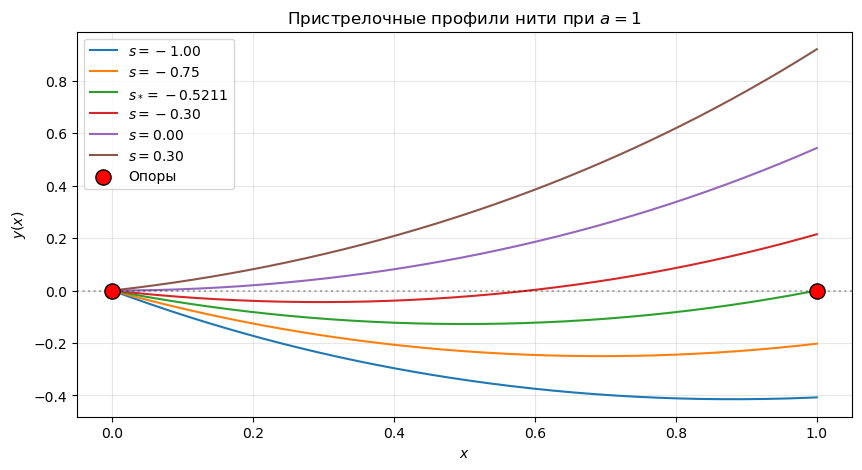

In [16]:
def solve_chain(s, a=1.0, T=1.0, n=300):
    """Возвращает (x, y) для профиля нити при данном s."""
    def rhs(t, y):
        return [y[1], (1.0 / a) * np.sqrt(1.0 + y[1]**2)]
    sol = solve_ivp(rhs, [0, T], [0.0, s], method='RK45',
                    rtol=1e-12, atol=1e-14, dense_output=True)
    t = np.linspace(0, T, n)
    return t, sol.sol(t)[0]

plt.figure(figsize=(10, 5))
for s_try in [-1.0, -0.75, s_exact, -0.3, 0.0, 0.3]:
    t, y = solve_chain(s_try)
    label = (f'$s_* = {s_try:.4f}$'
             if abs(s_try - s_exact) < 1e-3 else f'$s = {s_try:.2f}$')
    plt.plot(t, y, label=label)

plt.scatter([0, 1], [0, 0], color='red', s=120, zorder=10,
            label='Опоры', edgecolors='black')
plt.axhline(0, color='k', ls=':', alpha=0.3)
plt.legend()
plt.grid(alpha=0.3)
plt.xlabel('$x$')
plt.ylabel('$y(x)$')
plt.title('Пристрелочные профили нити при $a = 1$')
plt.show()

## Артефакт 2. Численный профиль против точного

Найденная форма нити при $s = s_*$ накладывается на точную кривую
$y(x) = \cosh(x - 1/2) - \cosh(1/2)$.
Справа — график модуля разности $|y_{\text{числ}} - y_{\text{точн}}|$ в логарифмической шкале.

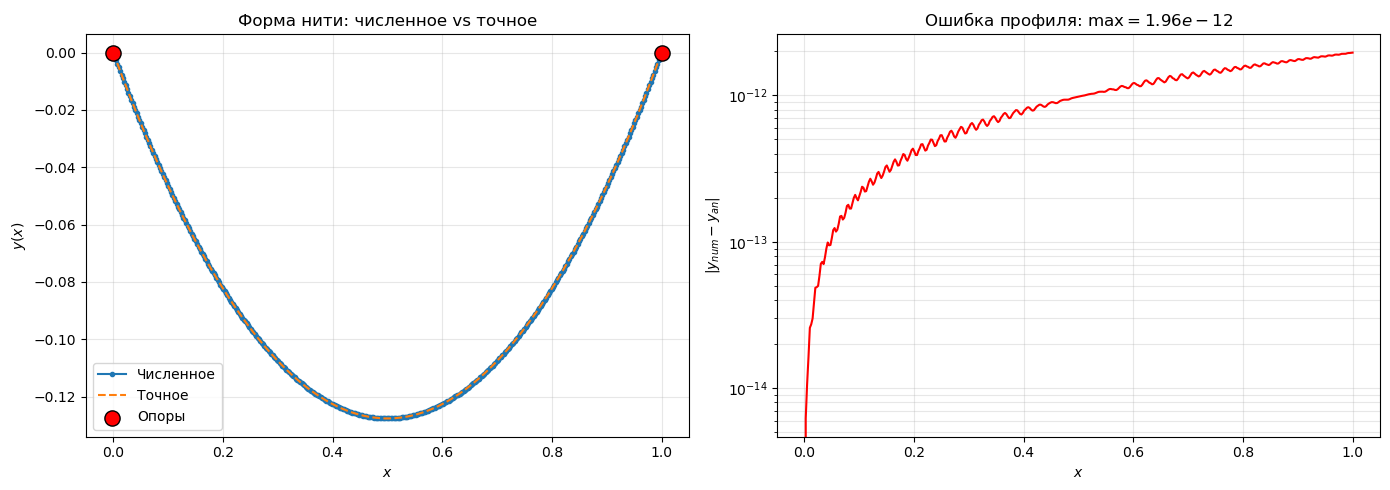

Невязка на правой опоре:  |y(1)| = 1.959e-12
Максимальная ошибка:      max|Δy| = 1.959e-12


In [17]:
t_num, y_num = solve_chain(s_newton, n=400)
y_ex = y_exact(t_num)
err = np.abs(y_num - y_ex)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(t_num, y_num, 'o-', markersize=3, label='Численное')
ax1.plot(t_num, y_ex, '--', label='Точное')
ax1.scatter([0, 1], [0, 0], color='red', s=120, zorder=10,
            label='Опоры', edgecolors='black')
ax1.legend()
ax1.grid(alpha=0.3)
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y(x)$')
ax1.set_title('Форма нити: численное vs точное')

ax2.semilogy(t_num, err, 'r-')
ax2.set_xlabel('$x$')
ax2.set_ylabel(r'$|y_{num} - y_{an}|$')
ax2.set_title(f'Ошибка профиля: $\\max = {err.max():.2e}$')
ax2.grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

print(f"Невязка на правой опоре:  |y(1)| = {abs(y_num[-1]):.3e}")
print(f"Максимальная ошибка:      max|Δy| = {err.max():.3e}")

## Артефакт 3. Уменьшение шага интегрирования

Ужесточаем допуски `rtol`, `atol` интегратора RK45 и **каждый раз заново подбираем** $s$ методом Ньютона.
Строим две зависимости в лог-шкале:

- **слева** — невязка на правой опоре $|y(1)|$,
- **справа** — максимальная ошибка профиля $\max_x |y_{\text{числ}}(x) - y_{\text{точн}}(x)|$.

rtol = 1e-04:  s = -0.5210954626,  |y(1)| = 1.45e-07,  max|Δy| = 1.45e-07
rtol = 1e-06:  s = -0.5210953207,  |y(1)| = 1.41e-08,  max|Δy| = 1.41e-08
rtol = 1e-08:  s = -0.5210953057,  |y(1)| = 1.45e-10,  max|Δy| = 1.45e-10
rtol = 1e-10:  s = -0.5210953055,  |y(1)| = 1.79e-12,  max|Δy| = 1.77e-12
rtol = 1e-12:  s = -0.5210953055,  |y(1)| = 1.53e-14,  max|Δy| = 6.26e-14
rtol = 1e-14:  s = -0.5210953055,  |y(1)| = 1.73e-16,  max|Δy| = 6.19e-14


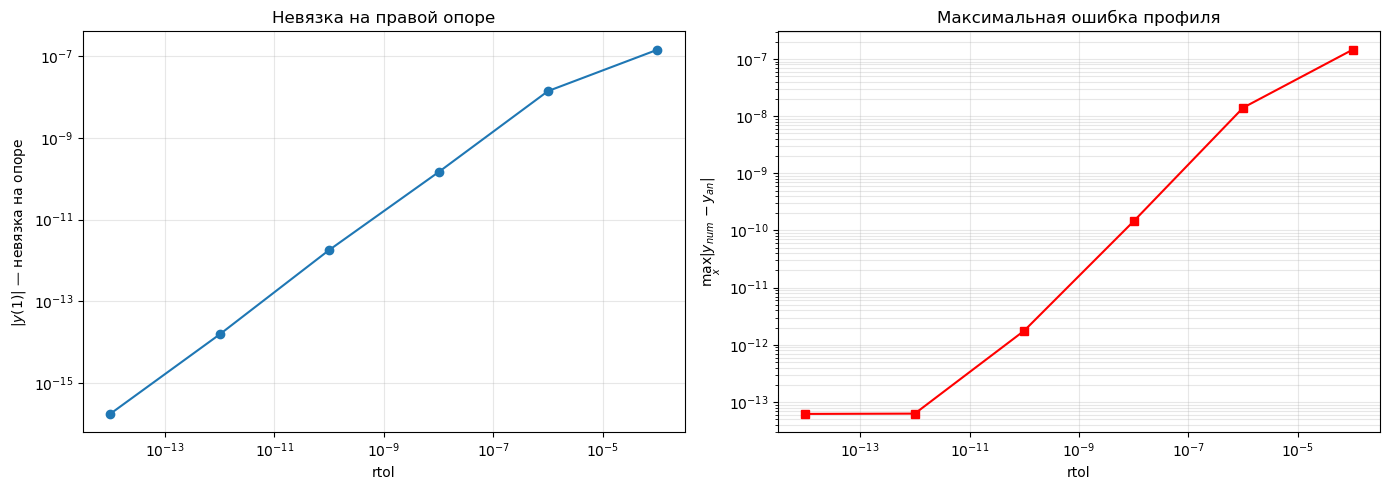

In [18]:
tolerances = [1e-4, 1e-6, 1e-8, 1e-10, 1e-12, 1e-14]
nevyazka_list, error_list = [], []

for tol in tolerances:
    f = lambda s: residual(s, rtol=tol, atol=tol * 1e-3)
    s_h, _, _ = newton_residual(f, s0=-0.5, tol=tol * 1e-2)

    t, y = solve_chain(s_h, n=400)
    y_ex = y_exact(t)

    nevyazka_list.append(abs(residual(s_h, rtol=1e-14, atol=1e-16)))
    error_list.append(np.max(np.abs(y - y_ex)))

    print(f"rtol = {tol:.0e}:  s = {s_h:+.10f},  "
          f"|y(1)| = {nevyazka_list[-1]:.2e},  max|Δy| = {error_list[-1]:.2e}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.loglog(tolerances, nevyazka_list, 'o-')
ax1.set_xlabel('rtol')
ax1.set_ylabel('$|y(1)|$ — невязка на опоре')
ax1.set_title('Невязка на правой опоре')
ax1.grid(alpha=0.3, which='both')

ax2.loglog(tolerances, error_list, 's-', color='red')
ax2.set_xlabel('rtol')
ax2.set_ylabel(r'$\max_x |y_{num} - y_{an}|$')
ax2.set_title('Максимальная ошибка профиля')
ax2.grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

# Нить между опорами — жёлтый уровень

## Постановка задачи

Теперь опоры находятся на **разных высотах**:

$$
y(0) = 0, \qquad y(1) = 0.2,
$$

а длина нити задана и равна

$$
L = \int_0^1 \sqrt{1 + (y')^2}\,dx = 1.2.
$$

## Неизвестные

Подбираем **два параметра**:

- начальный наклон $s = y'(0)$,
- параметр a.

## Вектор невязки

Дополняем систему уравнением для длины

$$
\ell'(x) = \sqrt{1 + (y')^2}, \qquad \ell(0) = 0.
$$

Тогда вектор состояния $\mathbf{w} = (y, y', \ell)$, а вектор невязки:

$$
\mathbf{R}(s, u) =
\begin{pmatrix}
y(1; s, u) - 0.2 \\[4pt]
\ell(1; s, u) - 1.2
\end{pmatrix}.
$$

## Метод решения

Двумерный метод Ньютона:

$$
\mathbf{x}_{k+1} = \mathbf{x}_k - J^{-1}(\mathbf{x}_k)\,\mathbf{R}(\mathbf{x}_k),
\qquad \mathbf{x} = (s, u).
$$

Якобиан $J$ вычисляется **численными разностями**, поправка находится
решением линейной системы $J\,\Delta\mathbf{x} = -\mathbf{R}$.

In [19]:
# ---------- Расширенная задача Коши: (y, y', ℓ) ----------
def integrate_chain_ext(s, u, T=1.0, rtol=1e-10, atol=1e-12):
    """u = ln a. Возвращает (y(T), ℓ(T))."""
    a = np.exp(u)
    def rhs(t, w):
        y, v, ell = w
        return [v,
                (1.0 / a) * np.sqrt(1.0 + v * v),
                np.sqrt(1.0 + v * v)]
    sol = solve_ivp(rhs, [0, T], [0.0, s, 0.0], method='RK45',
                    rtol=rtol, atol=atol)
    return sol.y[0, -1], sol.y[2, -1]

def residual_vec(s, u, L=1.2, **kw):
    """Вектор невязки (y(1) − 0.2, ℓ(1) − L)."""
    y1, ell1 = integrate_chain_ext(s, u, **kw)
    return np.array([y1 - 0.2, ell1 - L])

# ---------- Многомерный метод Ньютона ----------
def newton_2d(F, x0, tol=1e-10, max_iter=50, h=1e-6):
    """F: R^2 -> R^2. Якобиан — центральными разностями.
    Возвращает (x, итерации, история x_k, история ||F||)."""
    x = np.array(x0, dtype=float)
    history_x = [x.copy()]
    history_R = [np.linalg.norm(F(*x))]

    for k in range(max_iter):
        F0 = F(*x)
        if np.linalg.norm(F0) < tol:
            return x, k, history_x, history_R

        J = np.zeros((2, 2))
        for j in range(2):
            xp = x.copy(); xp[j] += h
            xm = x.copy(); xm[j] -= h
            J[:, j] = (F(*xp) - F(*xm)) / (2 * h)

        try:
            dx = np.linalg.solve(J, -F0)
        except np.linalg.LinAlgError:
            print(f"  Итерация {k}: вырожденный Якобиан")
            break

        x = x + dx
        history_x.append(x.copy())
        history_R.append(np.linalg.norm(F(*x)))

    return x, max_iter, history_x, history_R

# ---------- Запуск ----------
x0 = (0.0, 0.0)   # s0 = 0, u0 = ln(1) = 0, то есть a0 = 1
x_star, it, hist_x, hist_R = newton_2d(residual_vec, x0)

s_star, u_star = x_star
a_star = np.exp(u_star)

print(f"Ньютон сошёлся за {it} итераций")
print(f"s*  = {s_star:+.10f}")
print(f"u*  = ln(a*) = {u_star:+.10f}")
print(f"a*  = {a_star:.10f}")
print(f"R(s*, u*) = {residual_vec(s_star, u_star)}")

Ньютон сошёлся за 16 итераций
s*  = -0.9606492869
u*  = ln(a*) = -0.7144281723
a*  = 0.4894719254
R(s*, u*) = [9.53709334e-13 6.93667346e-13]


## Артефакт 1. Форма нити по итерациям Ньютона

На каждой итерации имеется приближение $(s_k, u_k)$.
Строим форму нити для всех итераций — видно, как профиль «подтягивается» к решению.

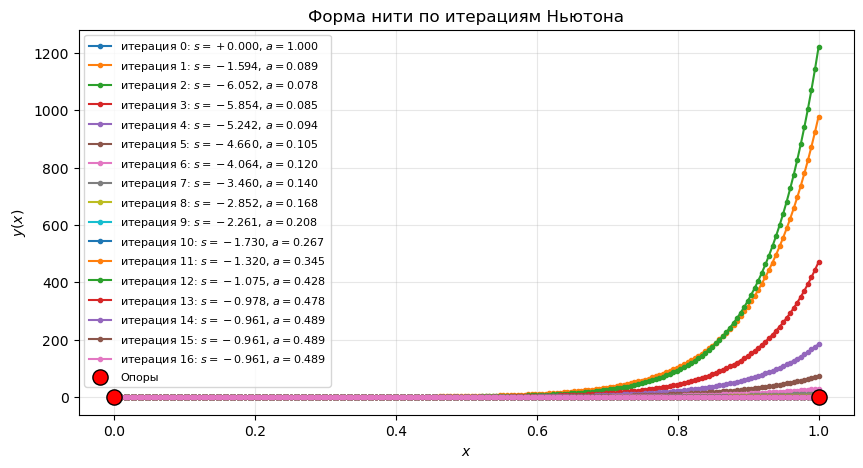

In [20]:
def solve_chain_profile(s, u, T=1.0, n=200):
    """Возвращает (x, y, ℓ) для профиля нити."""
    a = np.exp(u)
    def rhs(t, w):
        y, v, ell = w
        return [v,
                (1.0 / a) * np.sqrt(1.0 + v * v),
                np.sqrt(1.0 + v * v)]
    sol = solve_ivp(rhs, [0, T], [0.0, s, 0.0], method='RK45',
                    rtol=1e-12, atol=1e-14, dense_output=True)
    t = np.linspace(0, T, n)
    Y = sol.sol(t)
    return t, Y[0], Y[2]

plt.figure(figsize=(10, 5))
for k, xk in enumerate(hist_x):
    s_k, u_k = xk
    t, y, _ = solve_chain_profile(s_k, u_k)
    plt.plot(t, y, 'o-', markersize=3,
             label=f'итерация {k}: $s = {s_k:+.3f}$, $a = {np.exp(u_k):.3f}$')

plt.scatter([0, 1], [0, 0.2], color='red', s=120, zorder=10,
            label='Опоры', edgecolors='black')
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.xlabel('$x$')
plt.ylabel('$y(x)$')
plt.title('Форма нити по итерациям Ньютона')
plt.show()

## Артефакт 2. Графики обеих компонент невязки

- $R_1 = y(1) - 0.2$ — невязка по высоте правой опоры,
- $R_2 = \ell(1) - 1.2$ — невязка по длине нити.

Строим $|R_1|$ и $|R_2|$ по итерациям в лог-шкале.

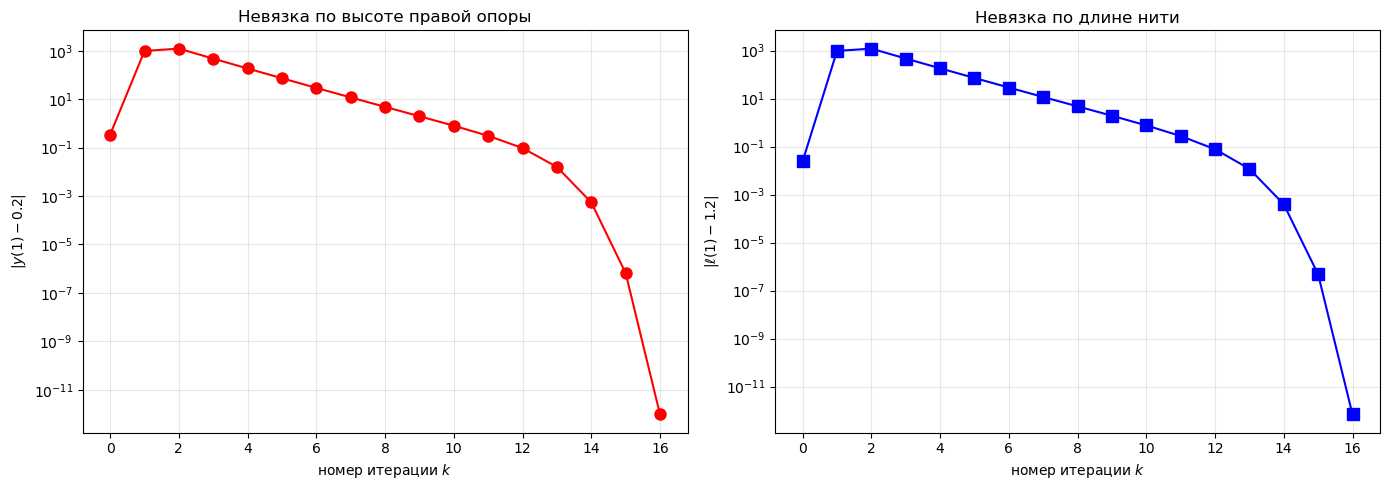

In [21]:
R1_hist, R2_hist = [], []
for xk in hist_x:
    r = residual_vec(*xk)
    R1_hist.append(abs(r[0]))
    R2_hist.append(abs(r[1]))

R1_hist = np.where(np.array(R1_hist) > 0, R1_hist, 1e-16)
R2_hist = np.where(np.array(R2_hist) > 0, R2_hist, 1e-16)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.semilogy(range(len(R1_hist)), R1_hist, 'ro-', markersize=8, lw=1.5)
ax1.set_xlabel('номер итерации $k$')
ax1.set_ylabel('$|y(1) - 0.2|$')
ax1.set_title('Невязка по высоте правой опоры')
ax1.grid(alpha=0.3, which='both')

ax2.semilogy(range(len(R2_hist)), R2_hist, 'bs-', markersize=8, lw=1.5)
ax2.set_xlabel('номер итерации $k$')
ax2.set_ylabel(r'$|\ell(1) - 1.2|$')
ax2.set_title('Невязка по длине нити')
ax2.grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

## Артефакт 3. Проверка найденных параметров более точным интегрированием

Берём найденные $(s_*, a_*)$ и интегрируем с более жёсткими допусками
`rtol = 1e-13`, `atol = 1e-15`. Смотрим ошибки:

- по высоте правого конца: $y(1) - 0.2$,
- по длине нити: $\ell(1) - 1.2$.

=== Проверочный расчёт (rtol=1e-13, atol=1e-15) ===
s*   = -0.960649286903
a*   = 0.489471925392
y(1) = 0.199999999998   (цель 0.2,  ошибка = -2.426e-12)
ℓ(1) = 1.200000000002  (цель 1.2,  ошибка = +2.004e-12)


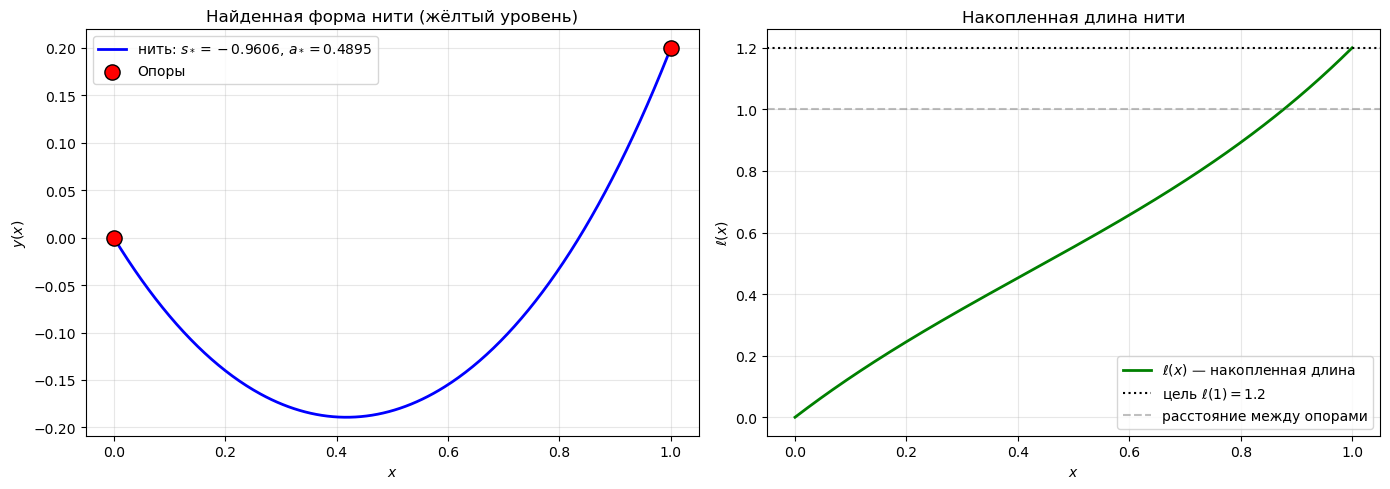

In [22]:
# Проверочный расчёт с высокой точностью
y1_check, ell1_check = integrate_chain_ext(s_star, u_star,
                                            rtol=1e-13, atol=1e-15)

print("=== Проверочный расчёт (rtol=1e-13, atol=1e-15) ===")
print(f"s*   = {s_star:+.12f}")
print(f"a*   = {a_star:.12f}")
print(f"y(1) = {y1_check:.12f}   (цель 0.2,  ошибка = {y1_check - 0.2:+.3e})")
print(f"ℓ(1) = {ell1_check:.12f}  (цель 1.2,  ошибка = {ell1_check - 1.2:+.3e})")

# Финальный профиль
t_fin, y_fin, ell_fin = solve_chain_profile(s_star, u_star, n=400)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(t_fin, y_fin, 'b-', lw=2,
         label=fr'нить: $s_* = {s_star:.4f}$, $a_* = {a_star:.4f}$')
ax1.scatter([0, 1], [0, 0.2], color='red', s=120, zorder=10,
            label='Опоры', edgecolors='black')
ax1.legend()
ax1.grid(alpha=0.3)
ax1.set_xlabel('$x$')
ax1.set_ylabel('$y(x)$')
ax1.set_title('Найденная форма нити (жёлтый уровень)')

ax2.plot(t_fin, ell_fin, 'g-', lw=2, label=r'$\ell(x)$ — накопленная длина')
ax2.axhline(1.2, color='k', ls=':', label=r'цель $\ell(1) = 1.2$')
ax2.axhline(1.0, color='gray', ls='--', alpha=0.5,
            label='расстояние между опорами')
ax2.legend()
ax2.grid(alpha=0.3)
ax2.set_xlabel('$x$')
ax2.set_ylabel(r'$\ell(x)$')
ax2.set_title('Накопленная длина нити')

plt.tight_layout()
plt.show()

## Ответ: как длина нити определяет провисание и натяжение

### Связь между длиной и параметром $a$

Параметр $a = H/q$ в уравнении нити

$$
y'' = \frac{1}{a}\sqrt{1 + (y')^2}
$$

играет роль **обратного масштаба провисания**:

- $a \to \infty$ — нить почти прямая, натяжение $H \to \infty$;
- $a \to 0$ — нить сильно провисает, натяжение $H \to 0$.

### Три режима

| Режим | Длина $L$ | Параметр $a$ | Натяжение $H$ | Провисание |
|:------|:---------:|:------------:|:-------------:|:----------:|
| Почти натянутая | $L \to d^+$ | $a \to \infty$ | $H \to \infty$ | $\to 0$ |
| Умеренная | $L \sim 1.2$ | $a \sim 0.5$ | $H \sim 0.5\,q$ | заметное |
| Сильно провисшая | $L \to \infty$ | $a \to 0$ | $H \to 0$ | $\to \infty$ |

где $d = \sqrt{1^2 + 0.2^2} \approx 1.0198$ — расстояние между опорами.

### Физический смысл

Избыток длины

$$
\Delta = L - d
$$

— это «запас», который нить тратит на провисание. При малых $\Delta$:

$$
H \sim \frac{q\, d^2}{2\,\Delta}.
$$

Отсюда видно:

- **$\Delta \to 0$** (нить почти натянута): $H \to \infty$, провисание $\to 0$,
  задача становится **плохо обусловленной** по $L$;
- **$\Delta$ растёт**: $H$ падает, провисание растёт, форма
  приближается к параболе.

### Найденные параметры (жёлтый уровень)

$$
s_* = -0.9606, \qquad a_* = 0.4895.
$$

- $a_* < 1$ — натяжение **меньше** веса нити, провисание **заметное**;
- $s_* < 0$ — нить сначала идёт **вниз**, потом поднимается к правой опоре
  (типичная цепная линия при разных высотах опор);
- максимальное провисание $y_{\min} \approx -0.19$ в точке $x \approx 0.4$.

### Итог

$$
\boxed{\;
\text{Длина } L \uparrow \;\Rightarrow\; a \downarrow \;\Rightarrow\;
H \downarrow \;\Rightarrow\; \text{провисание} \uparrow
\;}
$$

**Короткая нить — сильное натяжение и малое провисание.
Длинная нить — слабое натяжение и большое провисание.**